Khevin Jae Feliciano



# PCA of Bakery Sales Dataset

## 1. Import libraries

In [ ]:
import numpy as np                          # Numerical operations
import pandas as pd                         # Loading and managing the dataset
import matplotlib.pyplot as plt             # Plotting

from sklearn.preprocessing import StandardScaler   # Standardize feature values
from sklearn.decomposition import PCA              # Dimensionality reduction

## 2. Load dataset

In [ ]:
# ----- Optional: upload the file if running in Google Colab -----
# from google.colab import files
# uploaded = files.upload()
# print('File uploaded!')

bakery_dataset = pd.read_csv('bakery_sales_dataset.csv')

# Check the shape: (rows = transactions, columns = fields)
print('Dataset shape:', bakery_dataset.shape)
bakery_dataset.head()

Dataset shape: (19321, 40)


,Order_ID,Customer_ID,Customer_Age,Customer_Gender,Customer_Segment,Loyalty_Member,Date,Year,Month,Day,...,Storage_Type,Perishability,Store_ID,Units_Produced,Units_Sold,Unsold_Units,Stock_Available,Waste_Pct,Profit,Customer_Rating
0,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,...,Refrigerated,Very High,ST02,8,6,2,2,25.0,141.48,4
1,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,...,Dry Storage,Low,ST02,4,3,1,1,25.0,39.96,4
2,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Refrigerated,Very High,ST03,3,2,1,1,33.3,103.83,4
3,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Dry Storage,Low,ST03,13,10,3,2,23.1,79.73,4
4,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Room Temperature,Very High,ST03,4,3,1,1,25.0,10.08,4


## 3. Clean the data

In [ ]:
# 1. Missing values
missing_values = bakery_dataset.isnull().sum()
print("Missing values per column prior to cleaning:")
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else "No missing values detected.")

# Fill numeric gaps with the median, categorical gaps with the mode
for col in bakery_dataset.columns:
    if bakery_dataset[col].isnull().sum() > 0:
        if pd.api.types.is_numeric_dtype(bakery_dataset[col]):
            bakery_dataset[col] = bakery_dataset[col].fillna(bakery_dataset[col].median())
        else:
            bakery_dataset[col] = bakery_dataset[col].fillna(bakery_dataset[col].mode()[0])

# 2. Duplicates
duplicates_count = bakery_dataset.duplicated().sum()
print(f"\nDuplicate rows found: {duplicates_count}")
if duplicates_count > 0:
    bakery_dataset = bakery_dataset.drop_duplicates()
    print("Duplicates removed successfully.")

# FIX: reset the index so rows line up with the PCA output later
bakery_dataset = bakery_dataset.reset_index(drop=True)

# 3. Data types
if 'Date' in bakery_dataset.columns:
    bakery_dataset['Date'] = pd.to_datetime(bakery_dataset['Date'])
    print("\n'Date' column converted to datetime.")

print(f"\nCleaned dataset shape: {bakery_dataset.shape}")
bakery_dataset.head()

Missing values per column prior to cleaning:
Festival          16006
Promotion_Type    13826
dtype: int64

Duplicate rows found: 0

'Date' column converted to datetime.

Cleaned dataset shape: (19321, 40)


,Order_ID,Customer_ID,Customer_Age,Customer_Gender,Customer_Segment,Loyalty_Member,Date,Year,Month,Day,...,Storage_Type,Perishability,Store_ID,Units_Produced,Units_Sold,Unsold_Units,Stock_Available,Waste_Pct,Profit,Customer_Rating
0,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,...,Refrigerated,Very High,ST02,8,6,2,2,25.0,141.48,4
1,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,...,Dry Storage,Low,ST02,4,3,1,1,25.0,39.96,4
2,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Refrigerated,Very High,ST03,3,2,1,1,33.3,103.83,4
3,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Dry Storage,Low,ST03,13,10,3,2,23.1,79.73,4
4,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Room Temperature,Very High,ST03,4,3,1,1,25.0,10.08,4


## 4. Select features

In [ ]:
# Identifiers and date/time fields are not meaningful inputs for PCA
exclude_cols = ['Order_ID', 'Customer_ID', 'Date', 'Time']

numeric_features = [c for c in bakery_dataset.select_dtypes(include='number').columns
                    if c not in exclude_cols]
categorical_features = [c for c in bakery_dataset.select_dtypes(include=['object', 'category']).columns
                        if c not in exclude_cols]

print('Numerical features used for PCA:', numeric_features)
print('Categorical features (not used in PCA):', categorical_features)

if 'Customer_Segment' in bakery_dataset.columns:
    print('\nDistribution of Customer Segment:')
    print(bakery_dataset['Customer_Segment'].value_counts())

Numerical features used for PCA: ['Customer_Age', 'Year', 'Month', 'Day', 'Hour', 'Temperature', 'Quantity', 'Unit_Price', 'Cost_Price', 'Discount_Percentage', 'Selling_Price', 'Total_Bill', 'Shelf_Life_Days', 'Units_Produced', 'Units_Sold', 'Unsold_Units', 'Stock_Available', 'Waste_Pct', 'Profit', 'Customer_Rating']
Categorical features (not used in PCA): ['Customer_Gender', 'Customer_Segment', 'Loyalty_Member', 'Day_of_Week', 'Weekend', 'Season', 'Festival', 'Weather', 'Product', 'Category', 'Payment_Method', 'Promotion_Applied', 'Promotion_Type', 'Storage_Type', 'Perishability', 'Store_ID']

Distribution of Customer Segment:
Customer_Segment
Young Professional    7245
Family                5867
Student               4932
Senior Citizen        1277
Name: count, dtype: int64


## 5. Standardize the features
PCA is sensitive to scale, so every feature is rescaled to mean 0 and standard deviation 1.

In [ ]:
x_raw = bakery_dataset[numeric_features]

scaler = StandardScaler()
x = scaler.fit_transform(x_raw)        # learn mean & std, then apply

x_scaled_df = pd.DataFrame(x, columns=numeric_features)

print('Shape:', x.shape)
print('All means ~0:', np.allclose(x.mean(axis=0), 0))
print('All stds  ~1:', np.allclose(x.std(axis=0), 1))
x_scaled_df.head()

Shape: (19321, 20)
All means ~0: True
All stds  ~1: True


,Customer_Age,Year,Month,Day,Hour,Temperature,Quantity,Unit_Price,Cost_Price,Discount_Percentage,Selling_Price,Total_Bill,Shelf_Life_Days,Units_Produced,Units_Sold,Unsold_Units,Stock_Available,Waste_Pct,Profit,Customer_Rating
0,0.761508,-1.016333,-1.598404,-1.696214,-1.234618,-0.65675,2.116214,-0.224238,-0.296443,1.524013,-0.284342,1.144281,-0.560930,1.039448,0.972086,1.053694,1.154457,-0.716099,1.261306,0.181596
1,0.761508,-1.016333,-1.598404,-1.696214,-1.234618,-0.65675,0.433583,-0.517054,-0.555510,1.406265,-0.542946,-0.389295,0.027823,-0.060925,-0.015401,-0.223016,-0.174186,-0.716099,-0.294874,0.181596
2,-1.058861,-1.016333,-1.598404,-1.696214,0.541880,-0.65675,-0.688171,3.061451,3.142230,1.612323,2.619304,1.401557,-0.560930,-0.336018,-0.344563,-0.223016,-0.174186,-0.064294,0.684176,0.181596
3,-1.058861,-1.016333,-1.598404,-1.696214,0.541880,-0.65675,2.677091,-0.515696,-0.547173,2.142186,-0.555994,0.207402,-0.367896,2.414914,2.288736,2.330404,1.154457,-0.865307,0.314752,0.181596
4,-1.058861,-1.016333,-1.598404,-1.696214,0.541880,-0.65675,0.433583,-0.717997,-0.691790,1.111897,-0.722125,-0.749633,-0.580233,-0.060925,-0.015401,-0.223016,-0.174186,-0.716099,-0.752899,0.181596


## 6. Apply PCA

In [ ]:
n_features = x.shape[1]

# Reduce from n_features dimensions down to 2 principal components
pca = PCA(n_components=2)
principal_components = pca.fit_transform(x)

print(f'Reduced {n_features} features -> 2 components')
print('PCA output shape:', principal_components.shape)   # (number of rows, 2)

# One row per transaction, with its coordinates on PC1 and PC2
pca_df = pd.DataFrame(principal_components, columns=['PC1', 'PC2'])
print('\nFirst 5 rows of PCA result:')
print(pca_df.head())

Reduced 20 features -> 2 components
PCA output shape: (19321, 2)

First 5 rows of PCA result:
        PC1       PC2
0  2.160278  2.494883
1  0.894036 -0.755319
2 -3.879993  3.199460
3  4.326359  2.694528
4  1.214041 -1.195846


## 7. Explained variance ratio

In [ ]:
pc1_var, pc2_var = pca.explained_variance_ratio_

print('Explained variance per principal component:')
print('  PC1 : {:.1%}  - direction of greatest spread'.format(pc1_var))
print('  PC2 : {:.1%}  - direction of second greatest spread'.format(pc2_var))
print('  ' + '-' * 46)
print('  Total: {:.1%}  of original variance retained in 2D'.format(pc1_var + pc2_var))

Explained variance per principal component:
  PC1 : 23.3%  - direction of greatest spread
  PC2 : 20.2%  - direction of second greatest spread
  ----------------------------------------------
  Total: 43.5%  of original variance retained in 2D


## 8. What PC1 and PC2 are made of (loadings)
Each component is a weighted mix of the original features. Large absolute weights mean that feature drives the component; same signs move together, opposite signs trade off.

In [ ]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=numeric_features,
    columns=['PC1', 'PC2']
)
print(loadings.round(3))

for pc in ['PC1', 'PC2']:
    print(f'\n{pc} is driven mostly by:')
    print(loadings[pc].abs().sort_values(ascending=False).head(3).round(3))

                       PC1    PC2
Customer_Age        -0.002 -0.010
Year                -0.001 -0.005
Month                0.005  0.016
Day                  0.011  0.008
Hour                 0.007  0.002
Temperature         -0.010 -0.011
Quantity             0.318  0.235
Unit_Price          -0.346  0.311
Cost_Price          -0.347  0.304
Discount_Percentage  0.039  0.013
Selling_Price       -0.347  0.310
Total_Bill          -0.172  0.420
Shelf_Life_Days     -0.024 -0.075
Units_Produced       0.367  0.279
Units_Sold           0.367  0.263
Unsold_Units         0.280  0.275
Stock_Available      0.253  0.258
Waste_Pct           -0.281 -0.104
Profit              -0.129  0.421
Customer_Rating     -0.000 -0.003

PC1 is driven mostly by:
Units_Produced    0.367
Units_Sold        0.367
Selling_Price     0.347
Name: PC1, dtype: float64

PC2 is driven mostly by:
Profit        0.421
Total_Bill    0.420
Unit_Price    0.311
Name: PC2, dtype: float64


## 9. Visualize the PCA result

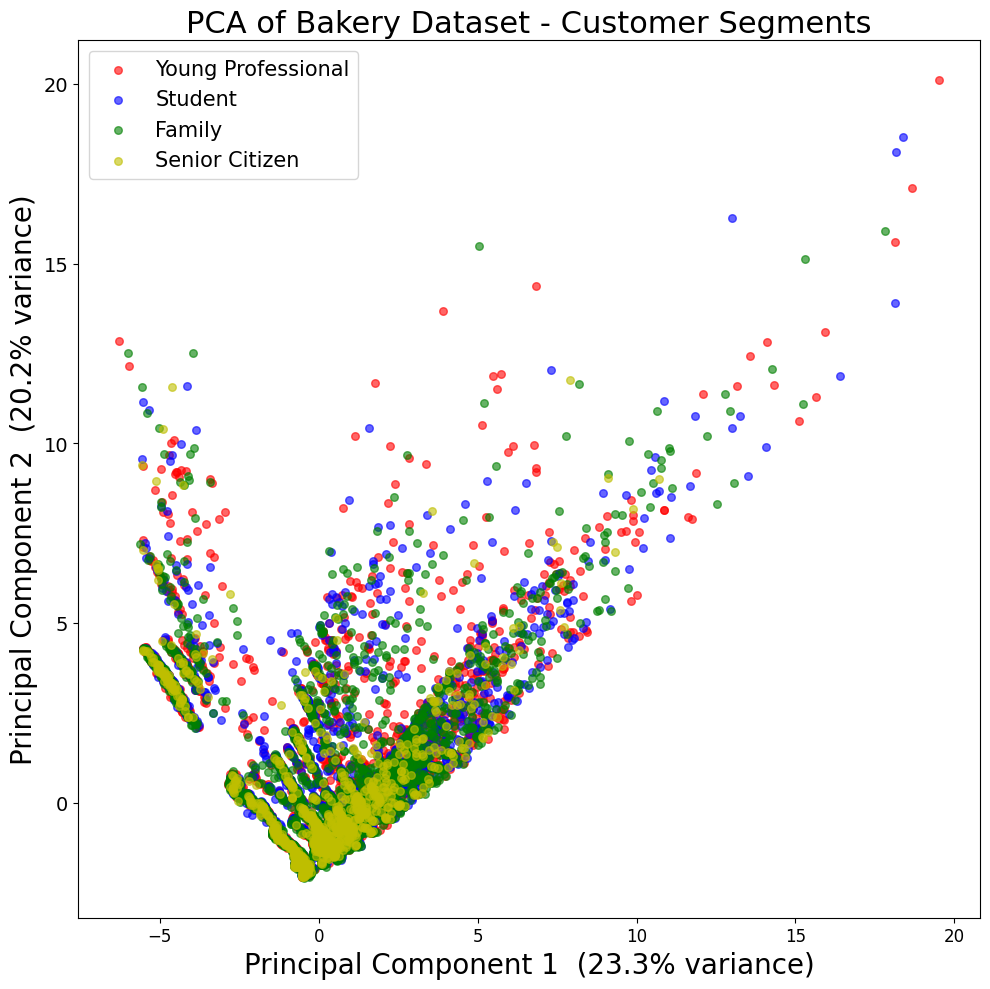

Plot saved as pca_bakery.png


In [ ]:
plt.figure(figsize=(10, 10))

plt.xlabel('Principal Component 1  ({:.1%} variance)'.format(pc1_var), fontsize=20)
plt.ylabel('Principal Component 2  ({:.1%} variance)'.format(pc2_var), fontsize=20)
plt.title('PCA of Bakery Dataset - Customer Segments', fontsize=22)
plt.xticks(fontsize=12)
plt.yticks(fontsize=14)

colors = {
    'Young Professional': 'r',
    'Family': 'g',
    'Student': 'b',
    'Senior Citizen': 'y',
}

# Plot every segment that actually exists in the data
for segment in bakery_dataset['Customer_Segment'].dropna().unique():
    mask = bakery_dataset['Customer_Segment'] == segment   # indexes now match pca_df
    plt.scatter(
        pca_df.loc[mask, 'PC1'],
        pca_df.loc[mask, 'PC2'],
        c=colors.get(segment, 'gray'),   # gray for any unexpected segment
        s=30,
        alpha=0.6,
        label=segment
    )

plt.legend(prop={'size': 15})
plt.tight_layout()
plt.savefig('pca_bakery.png', dpi=150)
plt.show()

print('Plot saved as pca_bakery.png')

## Summary

| Component | Variance Explained | Role |
| :--- | :--- | :--- |
| **PC1** | **~23.3%** | Direction of overall volume/scale (Units Produced/Sold) |
| **PC2** | **~20.2%** | Direction of financial performance (Profit & Total Bill) |
| **Combined** | **~43.5%** | Total information retained in the 2D plot |

### What the plot tells us:
This PCA analysis successfully maps bakery transactions into a 2D plot where clear behavioral structures can be recognized. Four distinct customer segments were projected onto the plot, showing noticeable overlap, indicating that basic transaction features alone do not completely segregate these demographics. Senior citizens (yellow) are heavily concentrated in a dense, low-variability cluster at the bottom left, suggesting consistent purchasing patterns. While young professionals (red) and students (blue) display wider spreads along both axes, representing a more diverse range of shopping behaviors. The distinct diagonal shapes in the visualization reflect the discrete nature of transaction-level inputs like unit counts and price brackets.

### Key Takeaways:
* ✅ **PCA successfully reduced 20 transactional features to 2**, preserving approximately **43.5%** of the original variance.
* ✅ **PC1 captures business scale** (driven by units produced/sold and transaction volume), while **PC2 captures transactional profitability** (driven by profit and total bill margins).
* ✅ **The heavy overlap among segments suggests** that classification models may require the addition of non-linear models or categorical features (e.g., product categories, loyalty membership) to achieve accurate customer segmentation.